# Module 7: Production Model Monitoring & Drift Detection
### Retail Demand Forecasting for Inventory Optimization (Rossmann)
**Course:** IT4063E – Introduction to Business Analytics

This notebook demonstrates the complete post-deployment monitoring pipeline:
1. **Continuous Forecast Tracking:** Comparing actual sales vs predicted sales as new date batches arrive.
2. **Rolling Performance Metrics:** Tracking 7-day rolling MAE and MAPE over time.
3. **Evidently AI Drift Analysis:** Automated Data Drift & Regression Performance assessment.
4. **Retraining Trigger Engine:** Algorithmic rules for automated model retraining alerts.

In [1]:
import json
import os

import matplotlib.pyplot as plt
import pandas as pd
from evidently import DataDefinition, Dataset, Regression, Report
from evidently.presets import DataDriftPreset, RegressionPreset

print('Dependencies loaded.')

Dependencies loaded.


## 1. Load Simulated Inflow Data (Reference vs Current Windows)
- **Reference Period:** Validation Windows 1 & 2 (`2015-05-23` to `2015-06-19`)
- **Current Period:** Validation Window 3 (`2015-06-20` to `2015-07-03`)

In [2]:
from scripts.generate_monitoring_artifacts import (
    build_monitoring_datasets,
    compute_rolling_metrics,
    evaluate_retraining_triggers,
)

full_df, ref_df, curr_df = build_monitoring_datasets()
print(f'Reference rows: {len(ref_df)}, Current rows: {len(curr_df)}')
ref_df.head()

Reference rows: 72, Current rows: 36


,date,store_id,day_of_week,is_open,is_promo,is_school_holiday,sales_actual,sales_pred_lightgbm,sales_pred_naive,sales_lag_1,sales_lag_7,sales_rolling_mean_7,sales_rolling_mean_14
14,2015-05-23,101,5,1,1,0,12794.18,13219.15,9523.06,9073.16,9523.06,6957.64,7553.92
16,2015-05-25,101,0,1,1,0,9285.75,9125.03,7317.22,0.00,7317.22,7424.94,7616.23
17,2015-05-26,101,1,1,1,0,9050.14,9165.89,7015.35,9285.75,7015.35,7706.16,7604.76
18,2015-05-27,101,2,1,1,0,9652.12,9960.33,8162.10,9050.14,8162.10,7996.84,7574.48
19,2015-05-28,101,3,1,0,0,8432.87,8572.27,7612.56,9652.12,7612.56,8209.70,7608.70


## 2. Rolling Forecast Error Tracking (MAE & MAPE)
Evaluating whether model accuracy degrades over time as new promotional cycles occur.

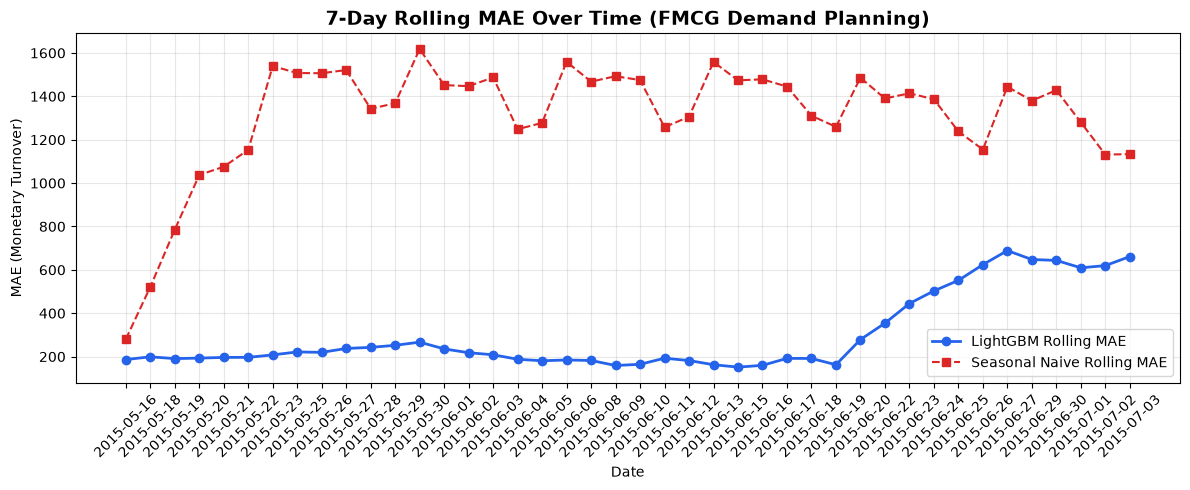

In [3]:
rolling = compute_rolling_metrics(full_df[full_df['is_open'] == 1])
rolling_df = pd.DataFrame(rolling)

plt.figure(figsize=(12, 5))
plt.plot(
        rolling_df["window_end_date"], rolling_df["lgb_mae"],
        marker="o", label="LightGBM Rolling MAE", color="#2563eb", linewidth=2,
    )
plt.plot(
        rolling_df["window_end_date"], rolling_df["naive_mae"],
        marker="s", label="Seasonal Naive Rolling MAE", color="#dc2626", linestyle="--",
    )
plt.title('7-Day Rolling MAE Over Time (FMCG Demand Planning)', fontsize=14, fontweight='bold')
plt.xlabel('Date')
plt.ylabel('MAE (Monetary Turnover)')
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

## 3. Evidently AI Data Drift & Regression Evaluation
Generating the interactive diagnostic suite evaluating:
- Target and residual distribution shifts
- Feature drift across lag variables and rolling statistics

In [4]:
eval_cols = [
    "sales_actual", "sales_pred_lightgbm", "sales_lag_1",
    "sales_lag_7", "sales_rolling_mean_7", "sales_rolling_mean_14",
    "is_promo", "day_of_week",
]
data_def = DataDefinition(
    regression=[Regression(target="sales_actual", prediction="sales_pred_lightgbm")]
)
ref_ds = Dataset.from_pandas(ref_df[eval_cols], data_definition=data_def)
curr_ds = Dataset.from_pandas(curr_df[eval_cols], data_definition=data_def)

report = Report([RegressionPreset(), DataDriftPreset()])
eval_res = report.run(reference_data=ref_ds, current_data=curr_ds)

# Save HTML report
os.makedirs('../reports', exist_ok=True)
eval_res.save_html('../reports/model_monitoring_report.html')
print('Evidently report saved to reports/model_monitoring_report.html')

/Users/hieunguyen/BA/it4063e-rossmann-demand-forecasting/.venv/lib/python3.12/site-packages/sklearn/metrics/_regression.py:1295: UndefinedMetricWarning: R^2 score is not well-defined with less than two samples.
  warnings.warn(msg, UndefinedMetricWarning)
/Users/hieunguyen/BA/it4063e-rossmann-demand-forecasting/.venv/lib/python3.12/site-packages/sklearn/metrics/_regression.py:1295: UndefinedMetricWarning: R^2 score is not well-defined with less than two samples.
  warnings.warn(msg, UndefinedMetricWarning)


Evidently report saved to reports/model_monitoring_report.html


## 4. Retraining Trigger Evaluation
Algorithmic decision rules to decide when human review or automatic retraining is required:
- **Rule 1 (Performance degradation):** Rolling MAE increases by more than 15% relative to the baseline.
- **Rule 2 (Covariate shift):** Greater than 25% of key predictors show statistically significant drift.
- **Rule 3 (Consecutive persistence):** Degradation must persist for 3 or more days to prevent knee-jerk retraining on single-day spikes.

In [5]:
triggers = evaluate_retraining_triggers(ref_df, curr_df)
print(json.dumps(triggers, indent=2))

{
  "status": "WARNING_PERFORMANCE",
  "summary": "Warning: Forecast error MAE has increased beyond threshold. Monitor closely.",
  "metrics": {
    "reference_mae": 200.2,
    "current_mae": 684.67,
    "mae_degradation_pct": 241.99,
    "reference_mape": 2.19,
    "current_mape": 7.39,
    "drifted_features_count": 0,
    "drifted_features": [],
    "share_drifted_features": 0.0
  },
  "thresholds": {
    "max_mae_degradation_pct": 15.0,
    "max_drifted_feature_share": 0.25,
    "consecutive_degraded_days_required": 3
  }
}
